# Daten anaylse (Analyse der Einflussgrößen)
- Welche Variablen beeinflussen Bodenatmung (soil.res) .

In [2]:
hainich.data <- read.csv("hainich.csv", sep=";")
#str(hainich.data)
#summary(hainich.data)
head(hainich.data)



,soil.res,temp.0,temp.5,temp.10,temp.15,smoi,lmoi,litter.d,ph.litter,ph.soil0,⋯,litno3,litnh4,litdoc,sno30,snh40,sdoc0,sno35,snh45,sdoc5,nn
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,4.3750,15.52,11.91,11.79,11.74,41.75939,0.6782141,0.3,6.45,4.23,⋯,0.036393668,0.018885578,0.4684278,0.01070368,0.002945600,0.09095835,0.004000000,0.003130156,0.11875886,2.49
2,4.3425,11.75,11.54,11.41,11.40,32.72151,0.5684457,1.5,6.42,4.30,⋯,0.002000000,0.003346766,0.3854520,0.00500000,0.003632943,0.08783729,0.004000000,0.001853513,0.05462559,1.06
3,2.9800,12.61,11.75,11.52,11.48,33.83690,0.6595609,1.0,6.32,4.27,⋯,0.017632441,0.004607981,0.3919999,0.01760351,0.002377711,0.06770848,0.014260353,0.002639287,0.04153205,1.58
4,2.5625,11.75,11.40,11.35,11.26,28.25263,0.5779671,1.5,5.74,3.90,⋯,0.016701030,0.006571442,0.3751276,0.01089270,0.002118255,0.09349080,0.013633983,0.002255407,0.05857811,1.36
5,2.6000,12.29,11.59,11.45,11.39,42.87905,0.6757647,1.5,6.24,4.05,⋯,0.007461533,0.010068415,0.5004978,0.02276019,0.008599232,0.06802427,0.014321943,0.001674059,0.04704889,2.77
6,6.2125,12.93,11.74,11.59,11.50,27.27465,0.6292582,2.0,5.54,4.23,⋯,0.038616580,0.017991253,0.7431942,0.01743749,0.008957436,0.08329230,0.006601767,0.001000000,0.05974198,1.60


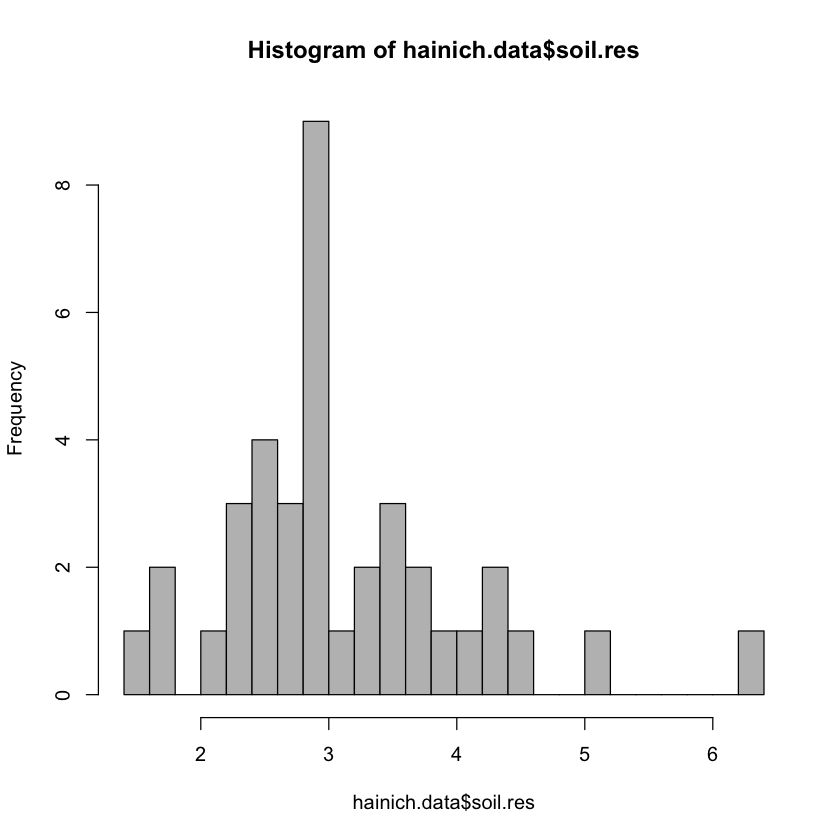

[1] 3.113026

[1] 2.9225

[1] 0.9041724

[1] 8.541006

[1] 0.3054519

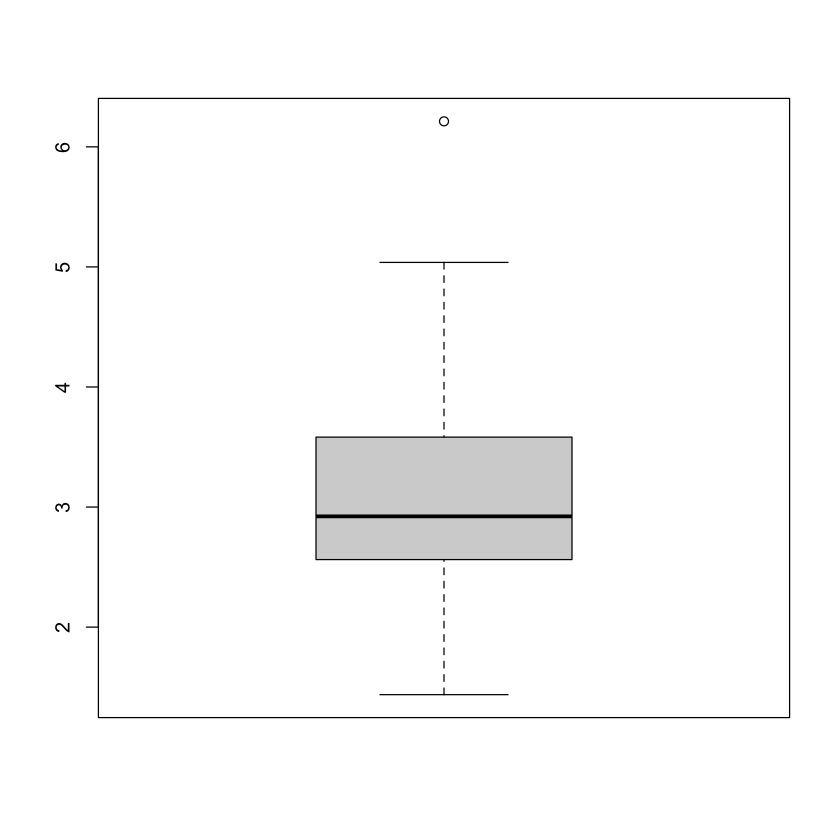

In [3]:
hist(hainich.data$soil.res, breaks=20, col="grey")
boxplot(hainich.data$soil.res)
mean(hainich.data$soil.res)
median(hainich.data$soil.res)
var(hainich.data$soil.res)
median(hainich.data$soil.res)^2

#Varianzkoeff
sd(hainich.data$soil.res) / mean(hainich.data$soil.res) # 0.305 -> moderate sreung
# Varianz ist viel kleiner als Median^2

Histogramm
- keine Gleichverteilung
- keine starke normakverteilung abeeer annährend glockenforme?
- mögliche ausreßer rechts?????
Boxplot
- Median ≈ 2.9 -3
- Die mittleren 50% der Werte liegen ungefähr zwischen 2.6 und 3.6
- Es gibt einige größere Werte (rechts) → mögliche hohe Bodenatmung

- Daten sind:
    - leicht rechts-schief (Die meisten Werte links/mittig aber einige großere werte weit rechts), mean> median -> rechts-schief
    - Streuung moderat, 
    - Paar hohe Werte könnten ökologisch wichtig sein?

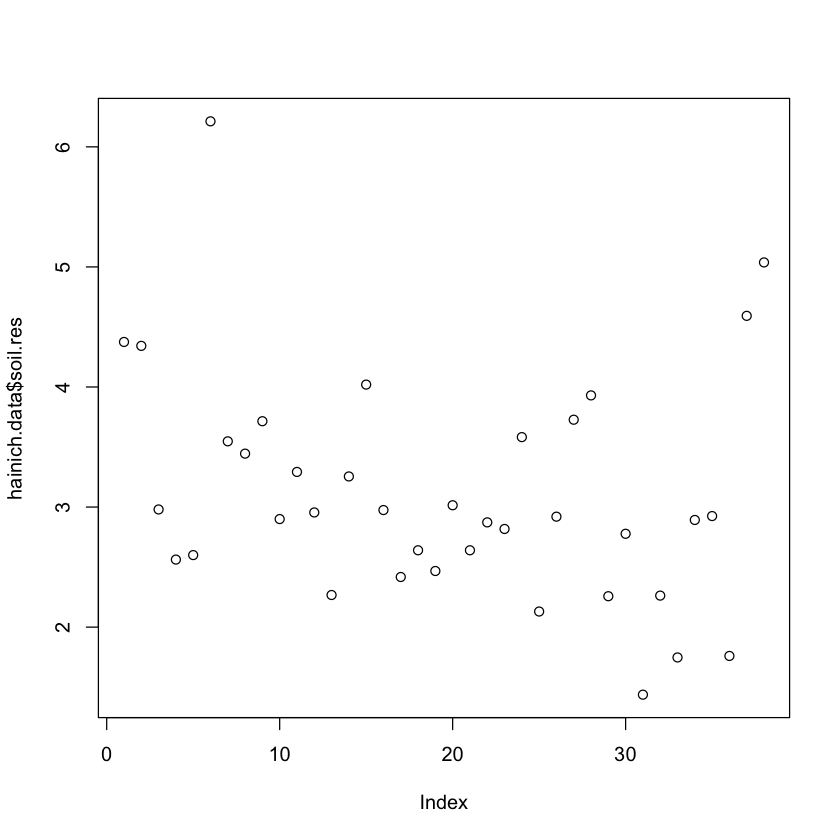

In [4]:
#Varianz überprufen
plot(hainich.data$soil.res)


### Normalverteilung
-> nicht normalverteilt

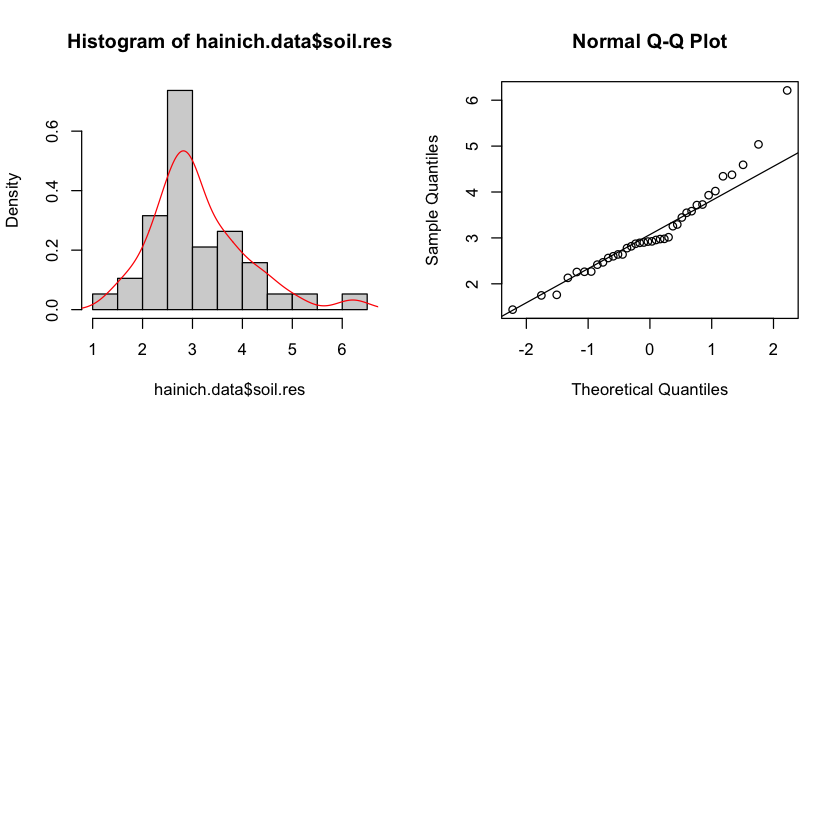

In [5]:
par(mfrow=c(2,2))
#Test aud normalverteilung
hist(hainich.data$soil.res, prob=TRUE)
lines(density(hainich.data$soil.res), col="red")

qqnorm(hainich.data$soil.res)
qqline(hainich.data$soil.res)
#nope nicht perf normal

### Transformation der Daten

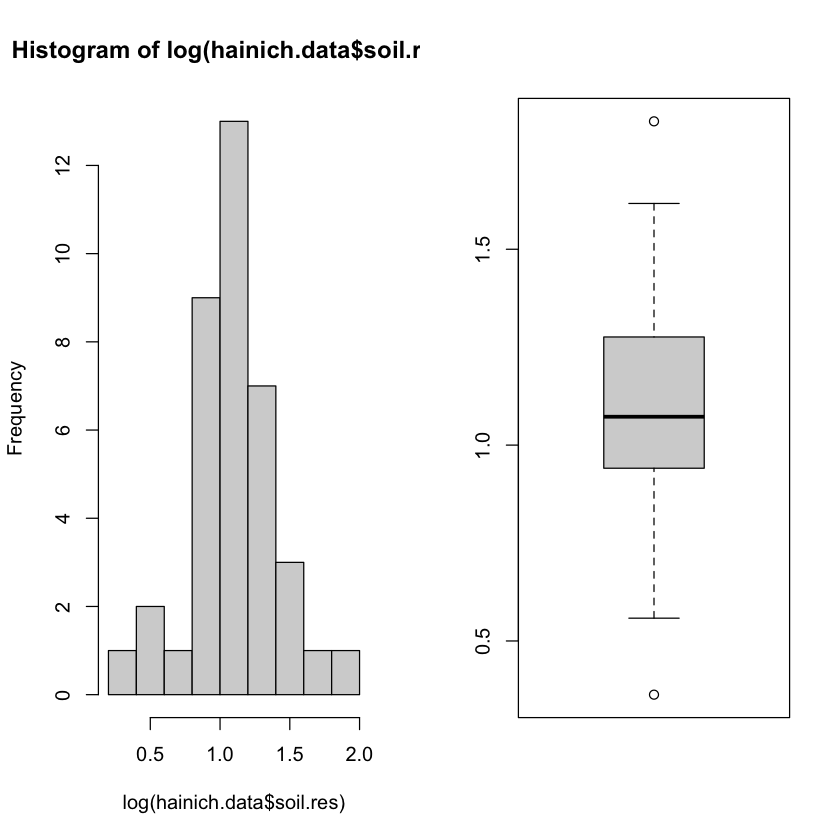

In [6]:
par(mfrow=c(1,2))
hist(log(hainich.data$soil.res))
boxplot(log(hainich.data$soil.res))

- log transf reduziert schiefe
- Median etwa in der Mitte der Box → symmetrisch

sqrt tranfs -> no

### Lognormal- vert
Punkte liegen deutlich näher an der Linie -> besser!

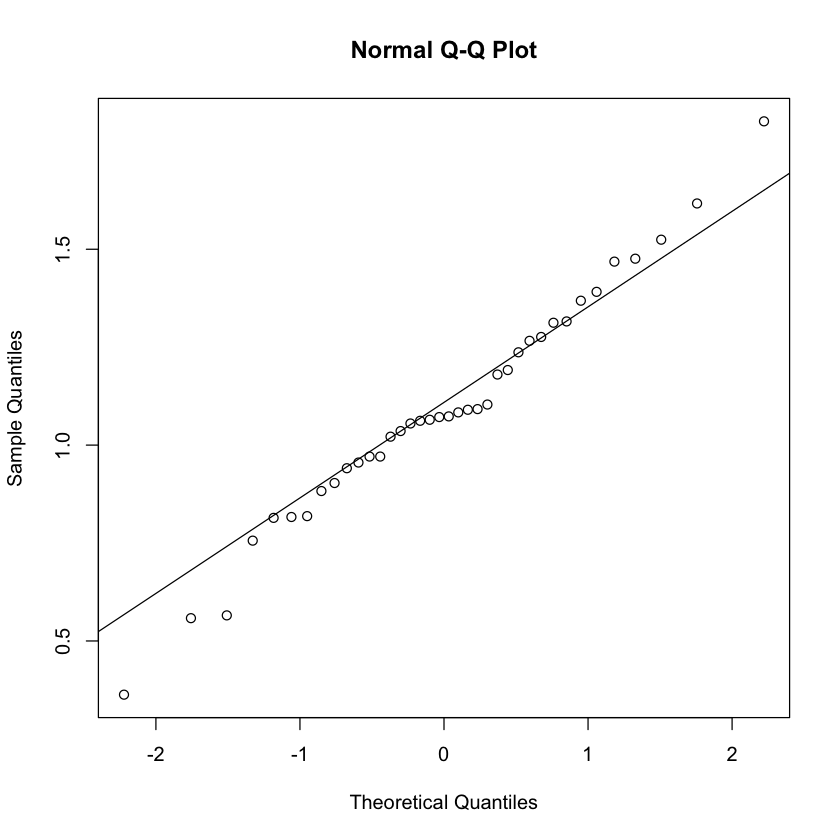

In [ ]:
qqnorm(log(hainich.data$soil.res))
qqline(log(hainich.data$soil.res))



## Annahmen:
- Transformation: log
    - y <- log(hainich.data$soil.res)
    - Log(soil.res) 
    - soil.res > 0 
- Verteilung: Lognormal
    - Wenn log(Y) normalverteilt ist → Y ist lognormal. log(soil.res) ≈ normal 
    - Alternativ Gamma?

### Scatterplotts 
- soil.res vs Umweltfaktoren -> Zusammenhänge sehen
- wichtigste einflussgrößen


In [11]:
y <- log(hainich.data$soil.res)

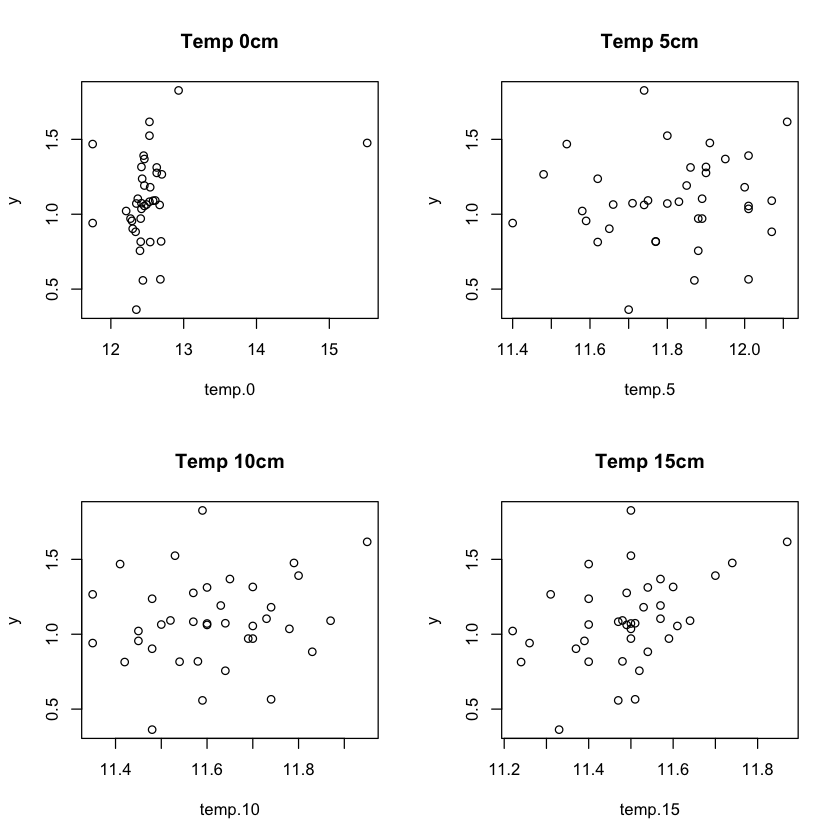

In [94]:
#Temperatur vs Bodenatmung
par(mfrow=c(2,2))
plot(y ~ temp.0, hainich.data, main="Temp 0cm")
plot(y ~ temp.5, hainich.data, main="Temp 5cm")
plot(y ~ temp.10, hainich.data, main="Temp 10cm")
plot(y ~ temp.15, hainich.data, main="Temp 15cm")


- Temperaturen liegen etwa 12–13.5 °C
- An der Oberfläche ist die temperatur ≈ gleich und bodenatmung sehr unterschiedlich -> oberflächetemp erklärt y nicht gut -> sonne wind etc
- temp 5 cm -> mehr temp unterschiede, leichter steigung, ~ mehr temp mehr bodenarmung -> hier leben mikroorgnaismen
- temp 10 cm -> temp ist stabiler? postive zsmhg
- temp 15 -> positiver trend
- je tiefer desto klarer den zsmhg

- Bio: Höhere Temperatur → mehr mikrobielle Aktivität → mehr CO₂ → höhere Bodenatmung

- postiver zhmg, moderate korrelation aber viele punkte streuen dh temp ist nicht das einzige faktor!

In [ ]:
cor(y, hainich.data$temp.0)
cor(y, hainich.data$temp.5)
cor(y, hainich.data$temp.10)
cor(y, hainich.data$temp.15) # temp 5 hat die höchste korrelation! das benutzen wir 

[1] 0.2630299

[1] 0.08963092

[1] 0.1775612

[1] 0.4348038

[1] -0.259031

[1] 0.4741594

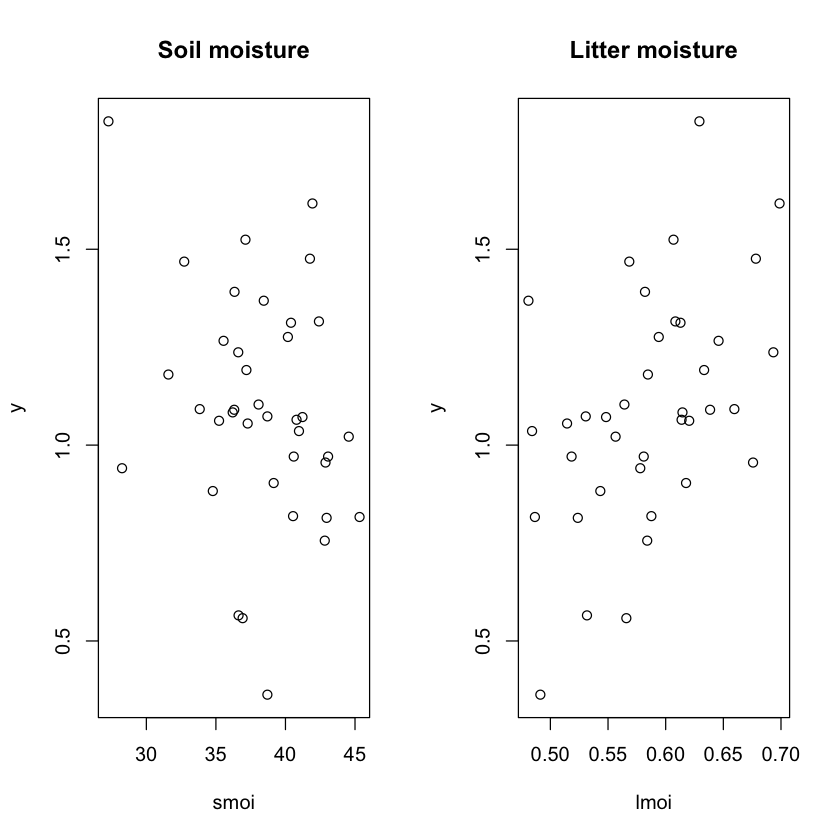

In [13]:
#Bodenfeuchte vs Bodenatmung
par(mfrow = c(1, 2))
plot(y ~ smoi, hainich.data, main="Soil moisture")
plot(y ~ lmoi, hainich.data, main="Litter moisture")
cor(y, hainich.data$smoi)
cor(y, hainich.data$lmoi)

- smoi = soil moisture (Bodenfeuchte) 
	- Bodenatmung ist bei mittlerer Feuchte am höchsten
	- Bei sehr niedriger oder sehr hoher Feuchte eher niedrigere Werte ->  ∩-Form Parabel (QUADRATUSH!) ->  Lin MODELL NICHT GUT!!! (Siehe unten)

- lmoi = litter moisture (Feuchte der Streuschicht) 
	- Zusammenhang stärker als bei smoi
	- Bodenatmung stegt mit smoi, aber bei sehr hoher Feuchte wieder Streuung / evtl. Sättigung
	- Streuschicht ist wichtig Feuchte steuert Aktivität direkt (lmoi kann ein starker Prädiktor sein!!)

	#lIN MODELL NICHT GUT!!!

In [ ]:
lm(soil.res ~ smoi, data=hainich.data)
lm(soil.res ~ lmoi, data=hainich.data) #starker positive effekt
lm(soil.res ~ smoi + I(smoi^2), data=hainich.data)
lm(soil.res ~ lmoi + I(lmoi^2), data=hainich.data) #lineare zusammenhang, quadratische term veschiebt nur leicht 



Call:
lm(formula = soil.res ~ smoi, data = hainich.data)

Coefficients:
(Intercept)         smoi  
    5.81114     -0.07045  



Call:
lm(formula = soil.res ~ lmoi, data = hainich.data)

Coefficients:
(Intercept)         lmoi  
     -1.174        7.323  



Call:
lm(formula = soil.res ~ smoi + I(smoi^2), data = hainich.data)

Coefficients:
(Intercept)         smoi    I(smoi^2)  
  16.286727    -0.646660     0.007815  



Call:
lm(formula = soil.res ~ lmoi + I(lmoi^2), data = hainich.data)

Coefficients:
(Intercept)         lmoi    I(lmoi^2)  
       5.97       -17.32        21.04  


[1] 0.3065886

[1] -0.01774499

[1] 0.1389108

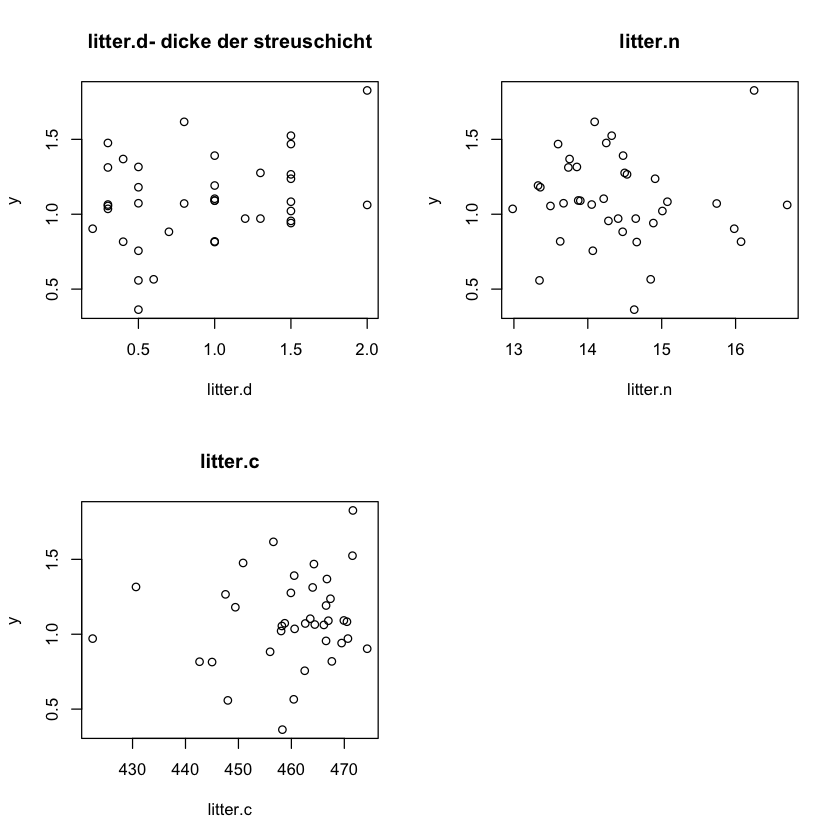

In [ ]:
#-Litter- Streu (organisches Material. Residuos)

par(mfrow = c(2, 2))
plot(y ~ litter.d, hainich.data, main="litter.d- dicke der streuschicht")
plot(y ~ litter.n, hainich.data, main="litter.n")
plot(y ~ litter.c, hainich.data, main="litter.c")

cor(y, hainich.data$litter.d) #höher
cor(y, hainich.data$litter.n) #neg korrelation
cor(y, hainich.data$litter.c)

- litter.d = dicke der streuschicht
- litter.n = Stickstoff in Streu
- litter.c = Kohlenstoff in Streu 

[1] -0.04565831

[1] 0.1516593

[1] -0.1826854

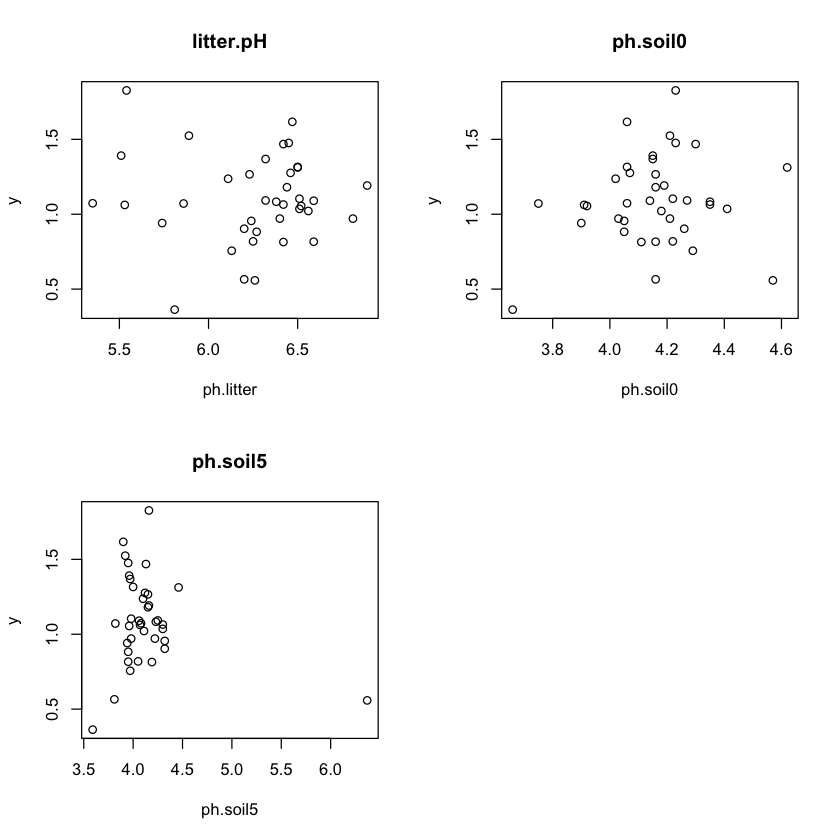

In [ ]:
#-pH-Wert
par(mfrow = c(2, 2))
plot(y ~ ph.litter, hainich.data, main="litter.pH")
plot(y ~ ph.soil0, hainich.data, main="ph.soil0")
plot(y ~ ph.soil5, hainich.data, main="ph.soil5")

cor(y, hainich.data$ph.litter) #negative korrelation
cor(y, hainich.data$ph.soil0) # pos
cor(y, hainich.data$ph.soil5) #negative korrelation

- ph.litter → Streu
- ph.soil0 → Oberfläche
- ph.soil5 → 5 cm

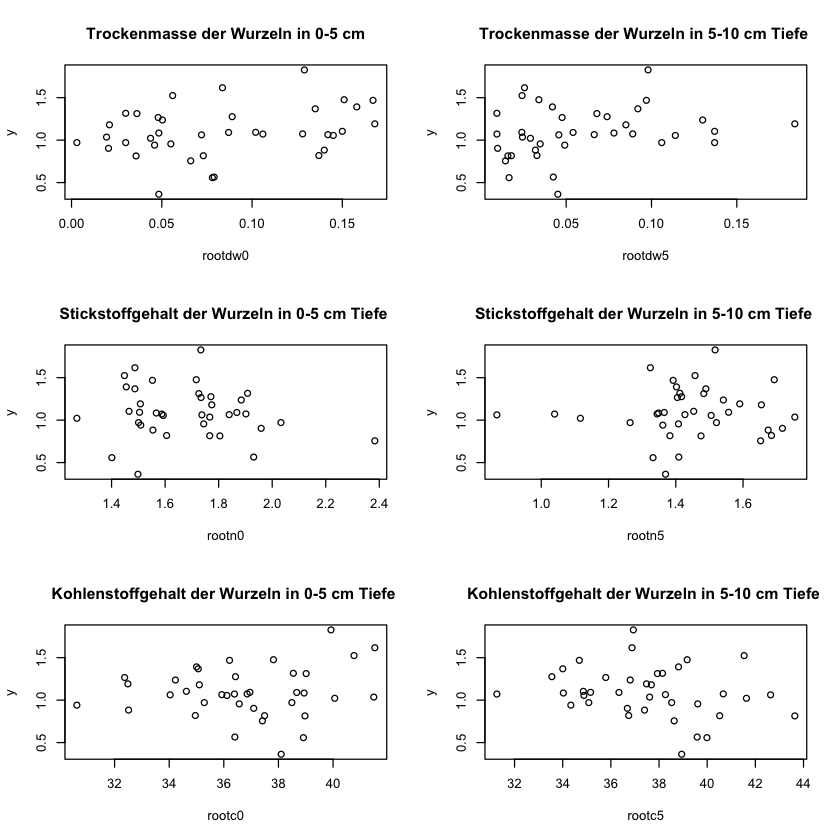

In [ ]:
# Würzeln
par(mfrow=c(3,2))
plot(y ~ rootdw0, hainich.data, main="Trockenmasse der Wurzeln in 0-5 cm")
plot(y ~ rootdw5, hainich.data, main="Trockenmasse der Wurzeln in 5-10 cm Tiefe ")


plot(y ~ rootn0, hainich.data, main="Stickstoffgehalt der Wurzeln in 0-5 cm Tiefe ")
plot(y ~ rootn5, hainich.data, main="Stickstoffgehalt der Wurzeln in 5-10 cm Tiefe ")


plot(y ~ rootc0, hainich.data, main="Kohlenstoffgehalt der Wurzeln in 0-5 cm Tiefe ")
plot(y ~ rootc5, hainich.data, main="Kohlenstoffgehalt der Wurzeln in 5-10 cm Tiefe ")


In [ ]:
# Würzeln
cor(y, hainich.data$rootdw0) #hoher
cor(y, hainich.data$rootdw5)

cor(y, hainich.data$rootn0) #neg
cor(y, hainich.data$rootn5) #pos, höher

cor(y, hainich.data$rootc0)
cor(y, hainich.data$rootc5) #neg

[1] 0.2853238

[1] 0.2464194

[1] -0.1469047

[1] 0.03874725

[1] 0.1333129

[1] -0.2300238

-
-
-


[1] 0.1389108

[1] -0.01774499

[1] 0.3065886

[1] 0.3260894

[1] 0.2691148

[1] 0.2297989

[1] 0.2138516

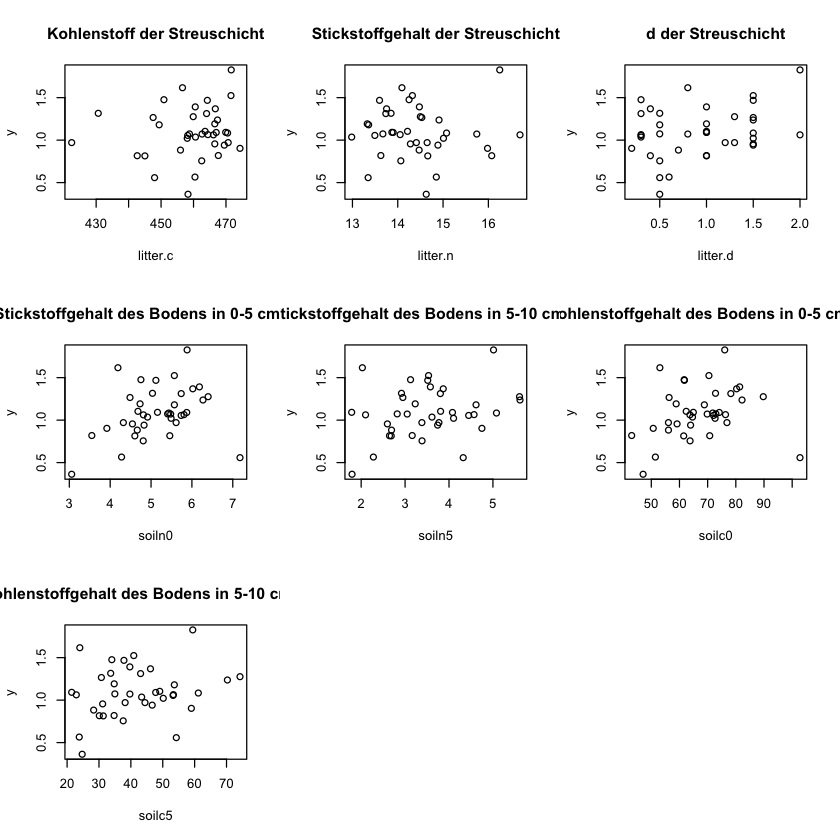

In [19]:
#Boden/streuschicht Nährstoffe
par(mfrow=c(3,3))
plot(y ~ litter.c, hainich.data, main="Kohlenstoff der Streuschicht")
plot(y ~ litter.n, hainich.data, main="Stickstoffgehalt der Streuschicht")
plot(y ~ litter.d, hainich.data, main="d der Streuschicht")
cor(y, hainich.data$litter.c)
cor(y, hainich.data$litter.n)
cor(y, hainich.data$litter.d)

plot(y ~ soiln0, hainich.data, main=" Stickstoffgehalt des Bodens in 0-5 cm Tiefe")
plot(y ~ soiln5, hainich.data, main=" Stickstoffgehalt des Bodens in 5-10 cm Tiefe")
cor(y, hainich.data$soiln0)
cor(y, hainich.data$soiln5)

plot(y ~ soilc0, hainich.data, main=" Kohlenstoffgehalt des Bodens in 0-5 cm Tiefe")
plot(y ~ soilc5, hainich.data, main=" Kohlenstoffgehalt des Bodens in 5-10 cm Tiefe")
cor(y, hainich.data$soilc0)
cor(y, hainich.data$soilc5)

[1] 0.1629472

[1] -0.001182912

[1] -0.268061

[1] 0.1925123

[1] 0.07152196

[1] -0.001711134

[1] 0.2757346

[1] 0.1551852

[1] 0.2020148

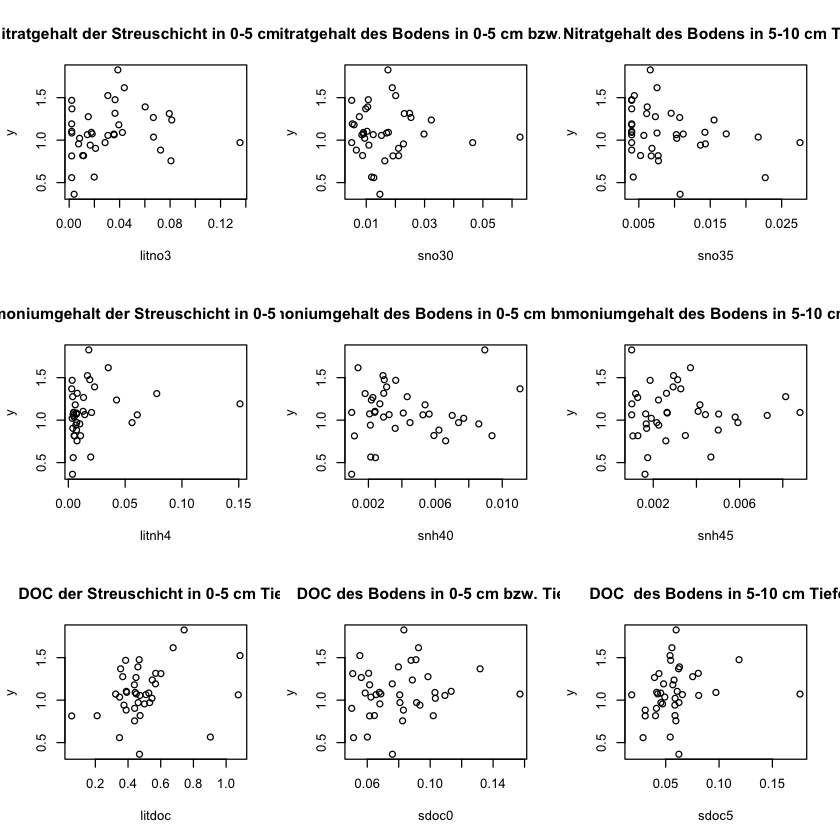

In [20]:
# Nährstoffe der Streuschicht bzw. des Bodens i
par(mfrow=c(3,3))


plot(y ~ litno3, hainich.data, main="Nitratgehalt der Streuschicht in 0-5 cm Tiefe")
plot(y ~ sno30, hainich.data, main="Nitratgehalt des Bodens in 0-5 cm bzw. Tiefe")
plot(y ~ sno35, hainich.data, main="Nitratgehalt des Bodens in 5-10 cm Tiefe")
cor(y, hainich.data$litno3)
cor(y, hainich.data$sno30)
cor(y, hainich.data$sno35)

plot(y ~ litnh4, hainich.data, main="Ammoniumgehalt der Streuschicht in 0-5 cm Tiefe")
plot(y ~ snh40, hainich.data, main="Ammoniumgehalt des Bodens in 0-5 cm bzw. Tiefe")
plot(y ~ snh45, hainich.data, main="Ammoniumgehalt des Bodens in 5-10 cm Tiefe")
cor(y, hainich.data$litnh4)
cor(y, hainich.data$snh40)
cor(y, hainich.data$snh45)

plot(y ~ litdoc, hainich.data, main=" DOC der Streuschicht in 0-5 cm Tiefe")
plot(y ~ sdoc0, hainich.data, main=" DOC des Bodens in 0-5 cm bzw. Tiefe")
plot(y ~ sdoc5, hainich.data, main=" DOC  des Bodens in 5-10 cm Tiefe")
cor(y, hainich.data$litdoc)
cor(y, hainich.data$sdoc0)
cor(y, hainich.data$sdoc5)

[1] -0.1518531

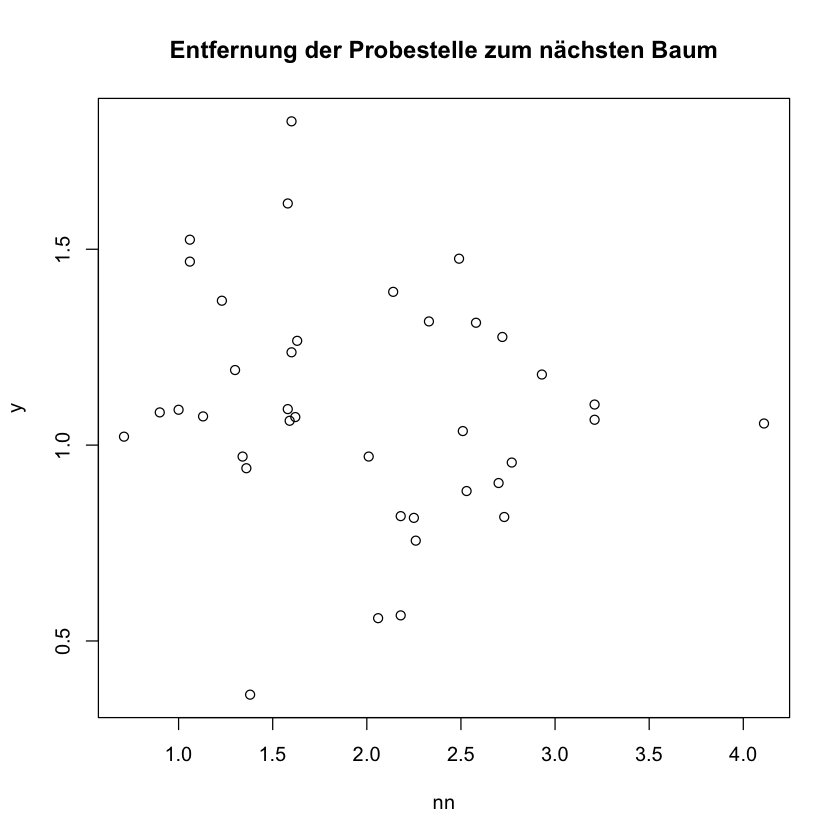

In [23]:
#nn – Entfernung der Probestelle zum nächsten Baum (nearest neighbour) 
plot(y ~ nn, hainich.data, main="Entfernung der Probestelle zum nächsten Baum")
cor(y, hainich.data$nn)

- was sagt das? ist das hier überhaupt sinnvoll?

### Korrelationen
- stärke messen
- Korrelationsmatrix
    - Welche Variablen sind linear verbunden?
    - korrelation von y mit einzelne variablen
    

In [ ]:
cor(y, hainich.data$smoi)
cor(y, hainich.data$lmoi)

[1] -0.259031

[1] 0.08963092

[1] 0.1775612

[1] 0.4348038

### Kandidaten
- mögliche Kandidaten 
    - temperatur 5 cm
    - lmoi - litter moisture?
    - org material
    - ...?
- Schwache Kandidaten:
    - ph
    - NN -> WAS DAS???
    - rootwdw 
- ACHTUNG AUF KOLINEARITÄT!!! D:

### Wichtigste Einflussgrößen
- wichtigste Prädiktoren auswählen

# Modell 
- Welches Modell, warum?